# 6.2 Событийный перенос в слое

# 6.2 平板中的事件驱动输运

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#D55E00", "#009E73"]),
    "figure.dpi": 110,
})

Matplotlib is building the font cache; this may take a moment.


## Двухскоростная gray-модель
Частица входит слева с направлением +1. После каждого рассеяния новое направление выбирается из −1 и +1 с равными вероятностями, включая прежнее направление. Границы поглощают выходящие частицы.

В расчёте $x^*=x/(v\tau)$, $t^*=t/\tau$, $L^*=L/(v\tau)$. Скорость равна ±1, среднее время между событиями равно 1. Это учебная модель с постоянными свойствами, без спектра реального материала.

## 双速度 gray 模型
粒子从左侧以 +1 方向进入。每次散射后，以相同概率从 −1 和 +1 中重新选择方向，也可能保持原方向。粒子到达边界后被吸收。

计算采用 $x^*=x/(v\tau)$、$t^*=t/\tau$、$L^*=L/(v\tau)$，速度为 ±1，平均事件间隔为 1。这是参数恒定的教学模型，不包含真实材料的声子谱。

## Одна траектория
Сравниваем время до рассеяния и время до границы. Если граница ближе, частица выходит до рассеяния. После рассеяния направление не обязано меняться.

## 单条轨迹
比较到散射事件和到边界的时间。如果先到达边界，粒子就在散射前离开。散射后方向不一定改变。

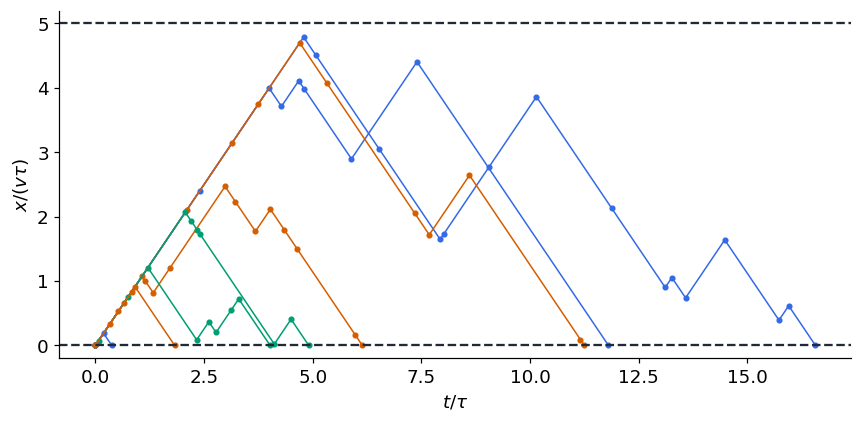

In [2]:
def single_path(length, rng):
    x, t, direction = 0.0, 0.0, 1.0
    positions, times = [x], [t]
    while True:
        ts = rng.exponential(1.0)
        tb = length - x if direction > 0 else x
        h = min(ts, tb)
        x = np.clip(x + direction * h, 0, length)
        t += h
        positions.append(x)
        times.append(t)
        if tb <= ts:
            break
        direction = rng.choice([-1.0, 1.0])
    return np.array(times), np.array(positions)

rng_paths = np.random.default_rng(42)
length = 5.0
paths = [single_path(length, rng_paths) for _ in range(8)]
fig, ax = plt.subplots()
for times, positions in paths:
    ax.plot(times, positions, "o-", markersize=3, linewidth=1)
ax.axhline(0, color="#202938", linestyle="--")
ax.axhline(length, color="#202938", linestyle="--")
ax.set(xlabel=r"$t/\tau$", ylabel=r"$x/(v\tau)$", ylim=(-0.2, length + 0.2))
fig.tight_layout()
plt.show()

## Ансамбль частиц
Одновременно обновляем все активные частицы. Массив `alive` исключает частицы, уже достигшие границы. Необязательный параметр `n_cells` включает накопление времени пребывания для расчёта температуры.

## 粒子集合
同时更新所有仍在运动的粒子。`alive` 排除已到达边界的粒子。可选参数 `n_cells` 用于累计各空间单元中的停留时间，供温度计算使用。

In [3]:
def event_transport(n, length, rng, n_cells=0):
    x = np.zeros(n)
    direction = np.ones(n)
    alive = np.ones(n, dtype=bool)
    transmitted = np.zeros(n, dtype=bool)
    elapsed = np.zeros(n)
    collisions = np.zeros(n, dtype=int)
    edges = np.linspace(0, length, n_cells + 1)
    residence = np.zeros(n_cells)
    signed_residence = np.zeros(n_cells)
    updates = 0
    while alive.any():
        ids = np.flatnonzero(alive)
        ts = rng.exponential(1.0, ids.size)
        tb = np.where(direction[ids] > 0, length - x[ids], x[ids])
        h = np.minimum(ts, tb)
        old_x = x[ids].copy()
        new_x = np.clip(old_x + direction[ids] * h, 0, length)
        if n_cells:
            lo = np.minimum(old_x, new_x)[:, None]
            hi = np.maximum(old_x, new_x)[:, None]
            overlap = np.maximum(0, np.minimum(hi, edges[1:])
                                 - np.maximum(lo, edges[:-1]))
            residence += overlap.sum(axis=0)
            signed_residence += (overlap * direction[ids, None]).sum(axis=0)
        elapsed[ids] += h
        x[ids] = new_x
        hit = tb <= ts
        transmitted[ids[hit]] = direction[ids[hit]] > 0
        alive[ids[hit]] = False
        scattered = ids[~hit]
        collisions[scattered] += 1
        direction[scattered] = rng.choice([-1.0, 1.0], scattered.size)
        updates += ids.size
    return {"transmitted": transmitted, "time": elapsed,
            "collisions": collisions, "x": x, "updates": updates,
            "residence": residence / n,
            "signed_residence": signed_residence / n}

In [4]:
rng = np.random.default_rng(2026)
N = 100_000
result = event_transport(N, length, rng)
p_mc = result["transmitted"].mean()
se = np.sqrt(p_mc * (1 - p_mc) / N)
p_exact = 1 / (1 + length / 2)
print(f"P_trans = {p_mc:.6f}, SE = {se:.6f}")
print(f"P_ref   = {p_exact:.6f}")
print(f"P_return = {1 - p_mc:.6f}")
print(f"mean(t/tau) = {result['time'].mean():.5f}")
print(f"mean(events) = {result['collisions'].mean():.5f}")

P_trans = 0.284350, SE = 0.001427
P_ref   = 0.285714
P_return = 0.715650
mean(t/tau) = 4.98477
mean(events) = 4.99623


## Аналитическая проверка
Для выбранной модели $P_{tr}=1/(1+L^*/2)$. Это вероятность дойти до правой границы после входа слева. Среднее время до выхода равно $L^*$, число рассеяний в среднем также равно $L^*$. Эти соотношения включают и возвращённые частицы.

## 解析校验
本模型满足 $P_{tr}=1/(1+L^*/2)$，它表示从左侧进入后到达右侧边界的概率。平均离开时间为 $L^*$，平均散射次数也为 $L^*$；统计包含从左侧返回的粒子。

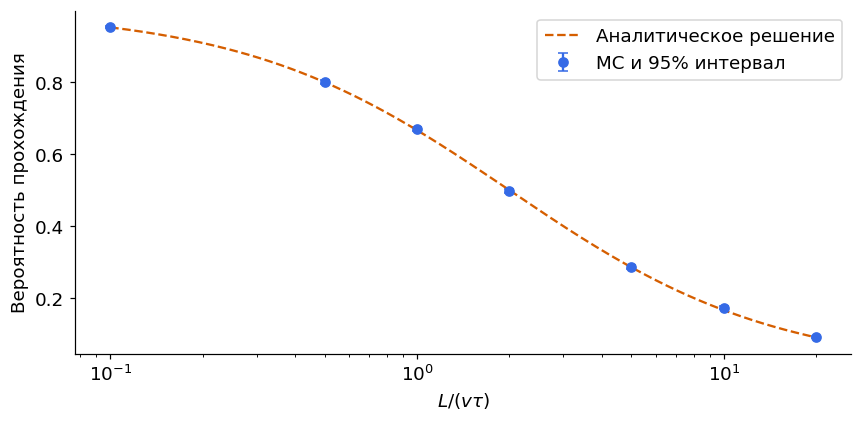

In [5]:
lengths = np.array([0.1, 0.5, 1, 2, 5, 10, 20])
rng_lengths = np.random.default_rng(2027)
N_length = 30_000
p_lengths, se_lengths = [], []
for value in lengths:
    run = event_transport(N_length, value, rng_lengths)
    p_value = run["transmitted"].mean()
    p_lengths.append(p_value)
    se_lengths.append(np.sqrt(p_value * (1 - p_value) / N_length))
p_lengths = np.array(p_lengths)
se_lengths = np.array(se_lengths)
grid = np.geomspace(0.1, 20, 200)
fig, ax = plt.subplots()
ax.errorbar(lengths, p_lengths, yerr=1.96 * se_lengths, fmt="o", capsize=3,
            label="MC и 95% интервал")
ax.plot(grid, 1 / (1 + grid / 2), "--", label="Аналитическое решение")
ax.set(xscale="log", xlabel=r"$L/(v\tau)$", ylabel="Вероятность прохождения")
ax.legend()
fig.tight_layout()
plt.show()

## Баллистический предел
При $L\ll v\tau$ большинство частиц проходит слой без рассеяния. При увеличении толщины вероятность прохождения уменьшается. Попробуйте заменить случайный выбор направления на обязательный разворот и объясните, почему изменился результат.

## 弹道极限
当 $L\ll v\tau$ 时，大多数粒子不经散射就穿过平板。随着厚度增大，透射概率减小。尝试把重新随机选择方向改为强制反向，解释结果为何改变。